# 04 - Evaluation and error analysis

Collects the measured metrics of the baseline and the neural models, draws figures, and
inspects errors on the test split. Every number shown is read from files produced by the
training and evaluation runs.

In [1]:
# Environment setup: works on Kaggle, Google Colab and a local checkout.
import os, subprocess, sys
from pathlib import Path

IN_KAGGLE = Path("/kaggle/working").exists()
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/HaoudarNouhaila/scigraph-nlp.git"

if IN_KAGGLE or IN_COLAB:
    base = Path("/kaggle/working") if IN_KAGGLE else Path("/content")
    ROOT = base / "scigraph-nlp"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print("project root:", ROOT.name)

project root: scigraph-nlp


In [2]:
subprocess.run([sys.executable, "scripts/make_report.py", "--ner", "outputs/ner", "--re", "outputs/re"], check=True)
import json, pandas as pd
summary = json.loads(Path("reports/metrics/summary.json").read_text())
pd.DataFrame(summary["rows"])

,system,task,setting,precision,recall,f1,macro_f1
0,Rule baseline (spaCy),NER,-,21.03,37.45,26.94,27.41
1,Rule baseline (spaCy),RE,A: gold entities,67.65,16.53,26.57,18.50
2,Rule baseline (spaCy),RE,B: predicted entities (boundaries),12.22,8.32,9.90,6.79
3,Rule baseline (spaCy),RE,B: predicted entities (strict),6.18,4.21,5.01,3.96
4,SciBERT span NER,NER,-,67.02,67.06,67.04,66.43
5,SciBERT marker RE,RE,A: gold entities,67.29,73.51,70.26,67.07
6,SciBERT NER + RE,RE,B: predicted entities (boundaries),45.29,50.31,47.67,45.90
7,SciBERT NER + RE,RE,B: predicted entities (strict),33.18,36.86,34.92,35.28


ner_per_type.png


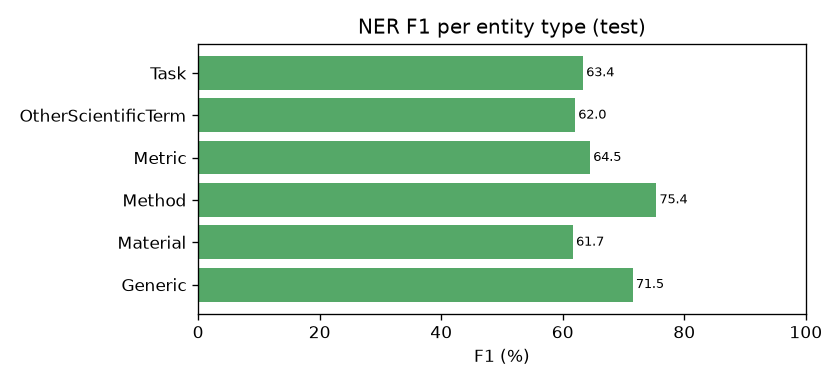

ner_training.png


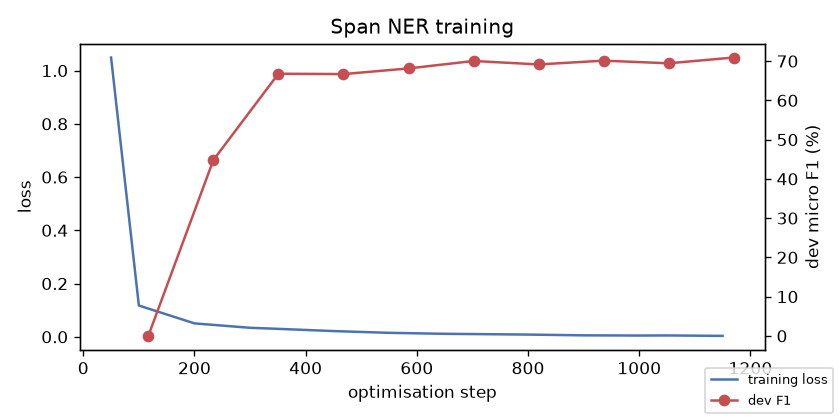

re_confusion.png


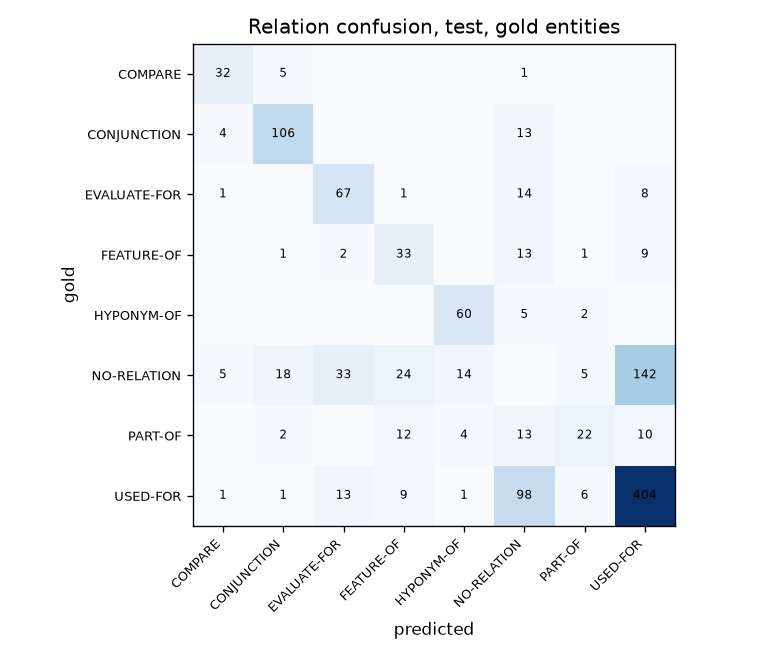

re_per_type.png


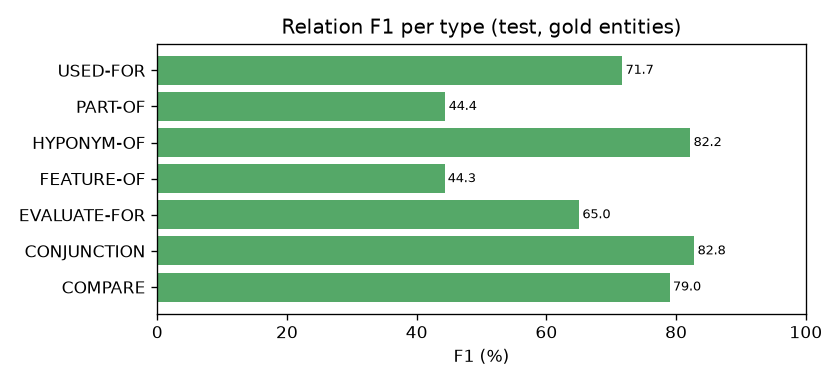

re_training.png


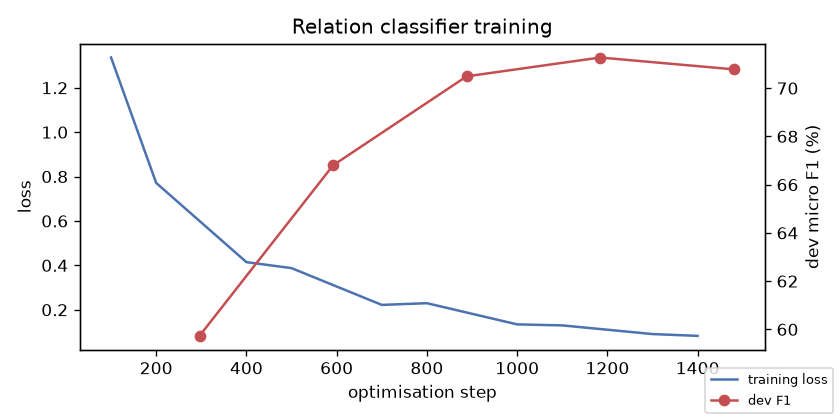

In [3]:
from IPython.display import Image, display
for f in sorted(Path("reports/figures").glob("*.png")):
    print(f.name); display(Image(filename=str(f)))

## NER errors

In [4]:
from collections import Counter
from scigraph.data.scierc import load_split, read_jsonl
test = load_split("data/processed", "test")
preds = {(r["doc_key"], r["sent_id"]): r["entities"] for r in read_jsonl("outputs/ner/predictions_test.jsonl")}
kinds = Counter()
examples = []
for s in test:
    gold = {(e.start, e.end): e.label for e in s.entities}
    pred = {(a, b): l for a, b, l in preds[(s.doc_key, s.sent_id)]}
    for span, lab in pred.items():
        if span in gold and gold[span] != lab:
            kinds[f"type: {gold[span]} -> {lab}"] += 1
        elif span not in gold:
            overl = any(not (span[1] < g[0] or g[1] < span[0]) for g in gold)
            kinds["boundary error" if overl else "spurious entity"] += 1
            if overl and len(examples) < 8:
                examples.append((" ".join(s.tokens[span[0]:span[1]+1]), lab, [" ".join(s.tokens[g[0]:g[1]+1]) for g in gold if not (span[1] < g[0] or g[1] < span[0])]))
    for span in gold:
        if span not in pred and not any(not (span[1] < p[0] or p[1] < span[0]) for p in pred):
            kinds["missed entity"] += 1
pd.Series(kinds).sort_values(ascending=False).head(15)

missed entity                            206
boundary error                           191
spurious entity                          161
type: OtherScientificTerm -> Method       35
type: Method -> OtherScientificTerm       33
type: Method -> Task                      27
type: Task -> Method                      17
type: OtherScientificTerm -> Material     15
type: OtherScientificTerm -> Task         14
type: Task -> OtherScientificTerm         12
type: Material -> OtherScientificTerm      7
type: Method -> Generic                    7
type: OtherScientificTerm -> Metric        6
type: Metric -> OtherScientificTerm        4
type: OtherScientificTerm -> Generic       4
dtype: int64

In [5]:
pd.DataFrame(examples, columns=["predicted span", "predicted type", "overlapping gold spans"])

,predicted span,predicted type,overlapping gold spans
0,Japanese information extraction -LRB- -LSB- 3 ...,Task,[Japanese information extraction]
1,recognition and classification of proper names,Task,[recognition and classification of proper name...
2,classification of proper names,Task,[recognition and classification of proper name...
3,proper names,OtherScientificTerm,[recognition and classification of proper name...
4,numerical and temporal expressions,OtherScientificTerm,[recognition and classification of proper name...
5,a priori geometric constraints,OtherScientificTerm,[priori geometric constraints]
6,3 -- D surface mesh,OtherScientificTerm,[iterative deformation of a 3 -- D surface mesh]
7,basic syntactic knowledge,OtherScientificTerm,[syntactic knowledge]


## Relation errors (Experiment B)

In [6]:
rel_preds = {(r["doc_key"], r["sent_id"]): r for r in read_jsonl("outputs/re/predictions_pred_entities_test.jsonl")}
cause = Counter()
for s in test:
    row = rel_preds[(s.doc_key, s.sent_id)]
    pred_spans = {(a, b) for a, b, _ in row["entities"]}
    pred_rels = {(a, b, c, d, l) for a, b, c, d, l in row["relations"]}
    for r in s.relations:
        key = (r.head.start, r.head.end, r.tail.start, r.tail.end, r.label)
        rev = (r.tail.start, r.tail.end, r.head.start, r.head.end, r.label)
        if key in pred_rels or rev in pred_rels and r.label in ("COMPARE", "CONJUNCTION"):
            cause["correct"] += 1
        elif (r.head.start, r.head.end) not in pred_spans or (r.tail.start, r.tail.end) not in pred_spans:
            cause["missed: argument not found by NER"] += 1
        elif any(p[:4] == key[:4] for p in pred_rels):
            cause["wrong relation type"] += 1
        elif any(p[:4] == rev[:4] for p in pred_rels):
            cause["wrong direction"] += 1
        else:
            cause["missed: pair predicted as NO-RELATION"] += 1
pd.Series(cause)

missed: pair predicted as NO-RELATION    108
missed: argument not found by NER        311
correct                                  490
wrong relation type                       40
wrong direction                           25
dtype: int64